<a href="https://colab.research.google.com/github/lnambiar18/Nambiar_Lohit_HW7_DSCI552/blob/main/Nambiar_Lohit_HW7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<center><h1>Nambiar_Lohit_HW7</h1></center>

Name: Lohit Nambiar
<br>
Github Username: lnambiar18
<br>
USC ID: 8395177707

## 1. Multi-class and Multi-Label Classification Using Support Vector Machines

Import packages

In [2]:
!pip install imbalanced-learn
import pandas as pd
import numpy as np
from sklearn.svm import SVC, LinearSVC
from sklearn.multiclass import OneVsRestClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, hamming_loss
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from sklearn.cluster import KMeans
from sklearn.metrics import calinski_harabasz_score

### (a) Download the Anuran Calls (MFCCs) Data Set

In [4]:
data = pd.read_csv('Frogs_MFCCs.csv')

train_data = data.sample(frac = 0.7, random_state = 1018)
test_data = data.drop(train_data.index)

train_data.head()

,MFCCs_ 1,MFCCs_ 2,MFCCs_ 3,MFCCs_ 4,MFCCs_ 5,MFCCs_ 6,MFCCs_ 7,MFCCs_ 8,MFCCs_ 9,MFCCs_10,...,MFCCs_17,MFCCs_18,MFCCs_19,MFCCs_20,MFCCs_21,MFCCs_22,Family,Genus,Species,RecordID
7047,1.000000,0.162286,0.824387,0.418936,-0.105082,0.052109,0.104860,0.197552,0.000114,-0.103839,...,-0.014966,-0.013978,0.028370,0.062859,-0.027910,-0.046417,Hylidae,Scinax,ScinaxRuber,56
6625,0.957282,0.523450,1.000000,0.258510,-0.364257,0.432092,0.237639,-0.355817,0.110812,0.241484,...,0.127553,-0.073178,-0.020316,0.064059,-0.014182,-0.051783,Leptodactylidae,Leptodactylus,LeptodactylusFuscus,45
5137,1.000000,0.691007,0.693166,0.453295,0.071342,0.103040,-0.081058,0.186156,0.173135,-0.285855,...,-0.160538,-0.035351,0.028677,0.033564,0.038174,-0.148297,Hylidae,Hypsiboas,HypsiboasCinerascens,36
2829,1.000000,0.450778,0.179596,0.536880,0.237089,-0.002735,-0.197700,0.040483,0.217061,-0.014972,...,0.166933,0.122329,-0.016720,-0.139801,0.016193,0.202066,Leptodactylidae,Adenomera,AdenomeraHylaedactylus,20
150,1.000000,0.258766,-0.057081,0.040170,0.183607,0.203282,0.099744,-0.006745,0.033179,0.170795,...,-0.050414,-0.163096,-0.135442,0.024000,0.121604,0.050082,Leptodactylidae,Adenomera,AdenomeraAndre,4


### (b) Train a classifier for each label

#### (i) Research

Exact match only counts a row as correct if Family, Genus, and Species are all predicted correctly. Hamming loss counts how many of the labels were wrong, and Hamming score shows how many were right. A lower Hamming loss and a higher Hamming score mean the classifier did better. I looked at both because exact match shows whether the whole prediction was right, while Hamming score and loss also show how well the classifier did when only some of the labels were wrong.

#### (ii) Train a SVM for each of the labels

In [ ]:
labels = ["Family", "Genus", "Species"]
features = [c for c in train_data.columns if c not in labels + ["RecordID"]]

X_train = train_data[features]
X_test = test_data[features]
y_test = test_data[labels]

for standardize in [False, True]:
    predictions = pd.DataFrame(index = test_data.index)

    for label in labels:
        svm = OneVsRestClassifier(SVC(kernel = "rbf"))
        if standardize:
          model = Pipeline([("scaler", StandardScaler()), ("onevsrestclassifier", svm)])
          params = {"onevsrestclassifier__estimator__C": [0.1, 1, 10], "onevsrestclassifier__estimator__gamma": [0.5, 2, 10]}

        else:
            model = svm
            params = {"estimator__C": [0.1, 1, 10], "estimator__gamma": [0.5, 2, 10]}

        search = GridSearchCV(model, params, cv = 10, scoring = "accuracy")
        search.fit(X_train, train_data[label])
        predictions[label] = search.predict(X_test)

        print(label, "Best Settings:", search.best_params_)
        print(label, "10-fold CV accuracy:", search.best_score_)

    exact_match = (y_test == predictions).all(axis=1).mean()
    loss = (y_test != predictions).to_numpy().mean()
    score = 1 - loss

    print("Standardized:", standardize)
    print("Exact match:", exact_match)
    print("Hamming loss:", loss)
    print("Hamming score:", score)

Family Best Settings: {'estimator__C': 10, 'estimator__gamma': 2}
Family 10-fold CV accuracy: 0.9928520148947584
Genus Best Settings: {'estimator__C': 10, 'estimator__gamma': 2}
Genus 10-fold CV accuracy: 0.9894770267285178
Species Best Settings: {'estimator__C': 10, 'estimator__gamma': 2}
Species 10-fold CV accuracy: 0.9900726592824007
Standardized: False
Exact match: 0.9865678554886521
Hamming loss: 0.00941794040450826
Hamming score: 0.9905820595954917
Family Best Settings: {'onevsrestclassifier__estimator__C': 10, 'onevsrestclassifier__estimator__gamma': 0.5}
Family 10-fold CV accuracy: 0.9775631922749218


#### (iii) Repeat 1(b)ii with L1-penalized SVMs

In [6]:
labels = ["Family", "Genus", "Species"]
features = [c for c in train_data.columns if c not in labels + ["RecordID"]]

X_train = train_data[features]
X_test = test_data[features]
y_test = test_data[labels]

predictions = pd.DataFrame(index = test_data.index)

for label in labels:
    model = Pipeline([("scale", StandardScaler()), ("svm", OneVsRestClassifier(LinearSVC(penalty = "l1", dual = False, max_iter = 20000)))])
    parameters = {"svm__estimator__C": [0.001, 0.01, 0.1, 1, 10, 100]}

    search = GridSearchCV(model, parameters, cv = 10, scoring = "accuracy")
    search.fit(X_train, train_data[label])
    predictions[label] = search.predict(X_test)

    print(label, "Best C:", search.best_params_["svm__estimator__C"])
    print(label, "10-fold CV accuracy:", search.best_score_)

exact_match = (y_test == predictions).all(axis=1).mean()
loss = (y_test != predictions).to_numpy().mean()
score = 1 - loss

print("Exact match:", exact_match)
print("Hamming loss:", loss)
print("Hamming score:", score)

Family Best C: 1
Family 10-fold CV accuracy: 0.9394379753226673
Genus Best C: 10
Genus 10-fold CV accuracy: 0.9533343589258101
Species Best C: 1
Species 10-fold CV accuracy: 0.9608831140143266
Exact match: 0.9133858267716536
Hamming loss: 0.05527250270186815
Hamming score: 0.9447274972981319


#### (iv) Repeat 1(b)iii by using SMOTE or any other method for imbalance

In [3]:
labels = ["Family", "Genus", "Species"]
features = [c for c in train_data.columns if c not in labels + ["RecordID"]]

X_train = train_data[features]
X_test = test_data[features]
y_test = test_data[labels]

models = [("RBF SVM", SVC(kernel = "rbf"), {"classifier__estimator__C": [0.1, 1, 10], "classifier__estimator__gamma": [0.5, 2, 10]}), ("L1 linear SVM", LinearSVC(penalty = "l1", dual = False, max_iter = 20000), {"classifier__estimator__C": [0.001, 0.01, 0.1, 1, 10, 100]})]

for name, svm, parameters in models:
    predictions = pd.DataFrame(index = test_data.index)

    for label in labels:
        model = ImbPipeline([("scale", StandardScaler()), ("smote", SMOTE(random_state = 1018)), ("classifier", OneVsRestClassifier(svm))])

        search = GridSearchCV(model, parameters, cv = 10, scoring = "accuracy")
        search.fit(X_train, train_data[label])
        predictions[label] = search.predict(X_test)

        print(name, label, "Best Settings:", search.best_params_)

    exact_match = (y_test == predictions).all(axis=1).mean()
    loss = (y_test != predictions).to_numpy().mean()

    print(name)
    print("Exact match:", exact_match)
    print("Hamming loss:", loss)
    print("Hamming score:", 1 - loss)

RBF SVM Family Best Settings: {'classifier__estimator__C': 10, 'classifier__estimator__gamma': 0.5}
RBF SVM Genus Best Settings: {'classifier__estimator__C': 10, 'classifier__estimator__gamma': 0.5}
RBF SVM Species Best Settings: {'classifier__estimator__C': 1, 'classifier__estimator__gamma': 0.5}
RBF SVM
Exact match: 0.9587772116720704
Hamming loss: 0.026709896557048016
Hamming score: 0.973290103442952
L1 linear SVM Family Best Settings: {'classifier__estimator__C': 10}
L1 linear SVM Genus Best Settings: {'classifier__estimator__C': 10}
L1 linear SVM Species Best Settings: {'classifier__estimator__C': 0.1}
L1 linear SVM
Exact match: 0.8596572487262621
Hamming loss: 0.07302763625135093
Hamming score: 0.9269723637486491


The regular RBF SVM did the best overall, with a 98.7% exact match and the lowest Hamming loss. The L1 linear SVM was lower, and SMOTE did not improve the overall scores. The SMOTE RBF model had a 95.9% exact match, while the SMOTE L1 model had 86.0%. So, based on these results, the RBF SVM worked best, and SMOTE did not help the overall predictions.

## 2. K-Means Clustering on a Multi-Class and Multi-Label Data Set

### (a) Use k-means clustering

In [5]:
labels = ["Family", "Genus", "Species"]
features = [c for c in data.columns if c not in labels + ["RecordID"]]

X = data[features]
y = data[labels]

distances = []
chosen_ks = []

for seed in range(50):
    best_score = -1
    best_k = None
    best_clusters = None

    for k in range(2, 51):
        model = KMeans(n_clusters =  k, n_init = 1, random_state = seed)
        clusters = model.fit_predict(X)
        score = calinski_harabasz_score(X, clusters)

        if score > best_score:
            best_score = score
            best_k = k
            best_clusters = clusters

    chosen_ks.append(best_k)
    predicted = np.empty(y.shape, dtype = object)

    for cluster in range(best_k):
        rows = best_clusters == cluster

        for column in range(len(labels)):
            predicted[rows, column] = y.iloc[rows, column].mode().iloc[0]

    distance = (predicted != y.to_numpy()).mean()
    distances.append(distance)

print("Chosen k values:", chosen_ks)
print("Average Hamming distance:", np.mean(distances))
print("Standard deviation:", np.std(distances, ddof = 1))

Chosen k values: [2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2]
Average Hamming distance: 0.29854065323141077
Standard deviation: 5.607473066727768e-17


### (b) Determine which family is the majority

In [6]:
for cluster in range(best_k):
    cluster_data = data[best_clusters == cluster]

    if len(cluster_data) > 0:
        print("Cluster", cluster)
        print("Family majority:", cluster_data["Family"].value_counts().idxmax())
        print("Genus majority:", cluster_data["Genus"].value_counts().idxmax())
        print("Species majority:", cluster_data["Species"].value_counts().idxmax())

Cluster 0
Family majority: Leptodactylidae
Genus majority: Adenomera
Species majority: AdenomeraHylaedactylus
Cluster 1
Family majority: Hylidae
Genus majority: Hypsiboas
Species majority: HypsiboasCordobae


### (c) Calculate the average Hamming distance, Hamming score, and Hamming loss

In [7]:
labels = ["Family", "Genus", "Species"]
true_labels = data[labels].to_numpy()
predicted_labels = np.empty(true_labels.shape, dtype = object)

for cluster in range(best_k):
    rows = best_clusters == cluster
    cluster_data = data[rows]

    majority = [cluster_data[label].value_counts().idxmax() for label in labels]

    predicted_labels[rows] = majority

distances = (true_labels != predicted_labels).sum(axis = 1)

average_distance = distances.mean()
hamming_loss = average_distance / len(labels)
hamming_score = 1 - hamming_loss

print("Average Hamming distance:", average_distance)
print("Hamming loss:", hamming_loss)
print("Hamming score:", hamming_score)

Average Hamming distance: 0.8956219596942321
Hamming loss: 0.2985406532314107
Hamming score: 0.7014593467685892


## 3. ISLR 12.6.2

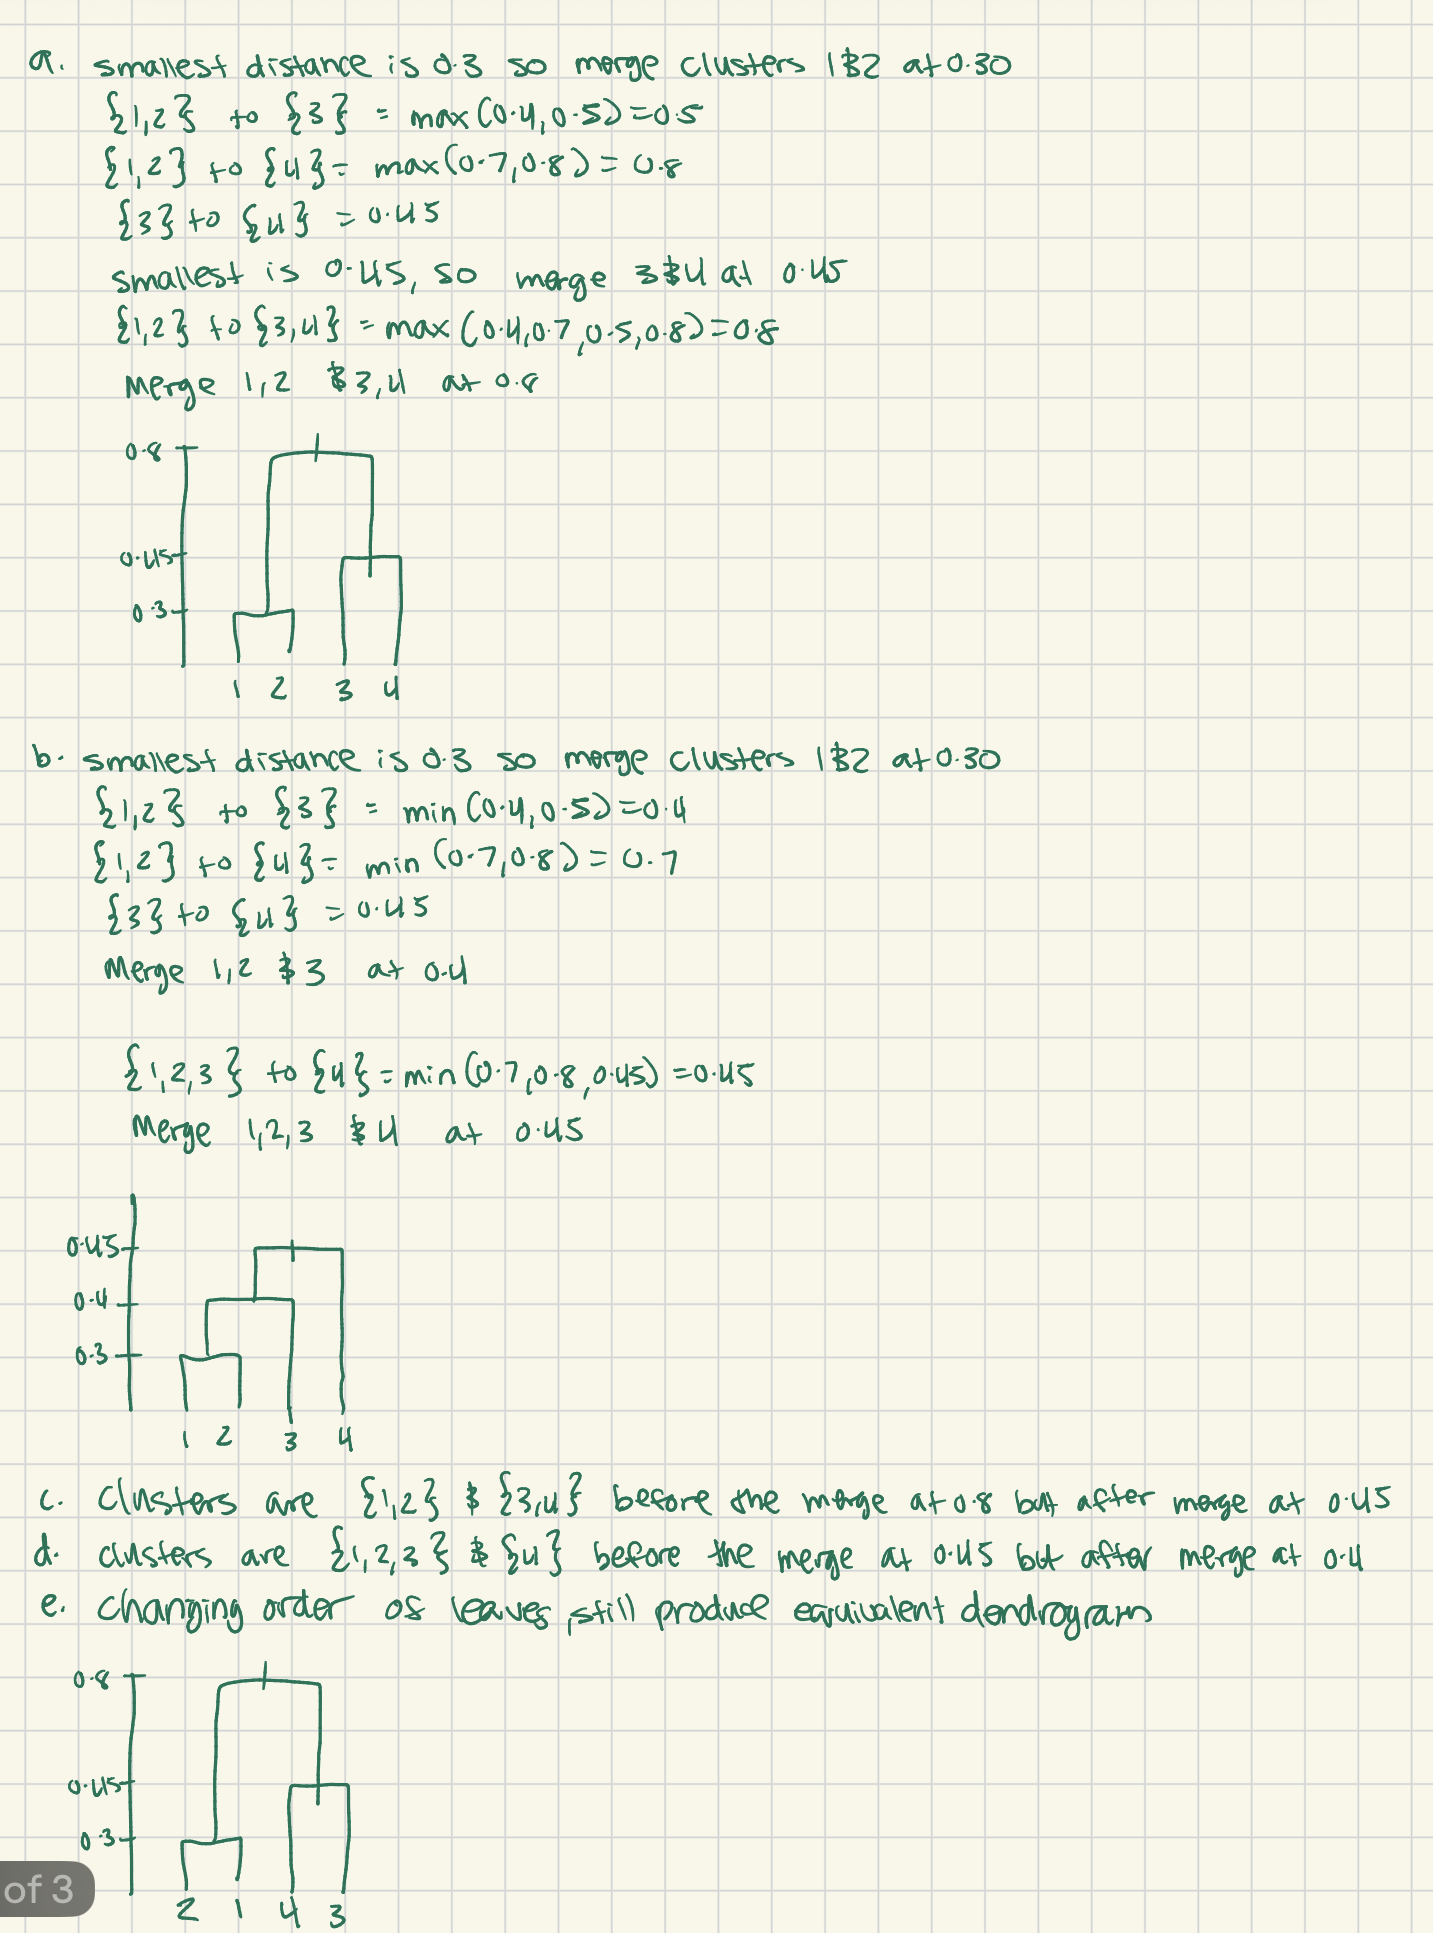